# <span style="color:#2B5DA5"><b>AMS 326 (Numerical Analysis) – FINAL EXAM</b></span> 🎓

---

## <span style="color:#C0392B"><b>READ THESE INSTRUCTIONS FIRST!</b></span> 📝

There are two types of problems:

- <span style="color:#2980B9"><b>Theoretical problems</b></span>: Solve these on **your own paper**.  
- <span style="color:#27AE60"><b>Coding problems</b></span>: Complete your answers by editing this Jupyter notebook.

**Submission Checklist** 🗂️  
- Submit your theoretical work as: <span style="color:#8E44AD"><b>Your-FirstName-LastName-AMS326-Final-Exam.pdf</b></span>  
- Submit your code as: <span style="color:#8E44AD"><b>Your-FirstName-LastName-AMS326-Final-Exam.ipynb</b></span>  

---

## <span style="color:#1ABC9C"><b>💡 What’s in This Notebook</b></span>

| <span style="color:#E67E22"><b>Q#</b></span> | <span style="color:#2980B9"><b>Topic / Task</b></span> | <span style="color:#CA6F1E"><b>Tasks</b></span> | <span style="color:#D35400"><b>Points</b></span> |
|:----------:|:---------------------------------------------|:--------------------|:-------:|
| <b>Q3b</b> | <span style="color:#34495E">Matrix population model (LU decomposition & application)</span>        | 3b.i–3b.ii          | 12      |
| <b>Q4bc</b> | <span style="color:#34495E">Random walk: Jacobi, Gauss-Seidel, SOR, simulation & animation</span> | 4b–4d               | 22      |
| <b>Q5d(ii)</b> | <span style="color:#34495E">Picard’s method: symbolic & numeric implementation</span>           | 5d(ii)              | 8       |
| <b>Q6bc</b> | <span style="color:#34495E">Nonconformist ODE: Euler’s method & analytic comparison</span>        | 6b–6c               | 10      |
| <b>Q7</b>   | <span style="color:#34495E">IVP: Euler, Taylor, Hermite, RK4, multistep, error analysis</span>    | 7a–7i               | 42      |
| <b>Q8</b>   | <span style="color:#34495E">Multistep: Adams-Bashforth, Predictor-Corrector, Gompertz model</span>| 8a–8b               | 22      |
|  | | | |
|   | <b>Total (coding)</b> |  | <span style="color:#E74C3C"><b>116</b></span> |

---

- <span style="color:#D35400"><b>Theoretical problems:</b></span> <b>84 points</b>
- <span style="color:#2980B9"><b>Coding problems:</b></span> <b>116 points</b>

---

### <span style="color:#8E44AD"><b>✨ Tips for Success</b></span>

- **Carefully read each prompt**—don’t skip instructions or comments in the code!
- Use Markdown cells to discuss and interpret your results.
- Keep your code organized and clearly labeled.
- **Do your own work!** Academic integrity is essential.
- Ask for clarification if you get stuck (but don’t share solutions!).

---

> <span style="color:#27AE60"><b>Good luck! Give your best, and enjoy coding!</b></span> 🍀

## **[4+4 marks] Question 3b**

We will use the LU decomposition (or $P^T LU$ decomposition) to solve the age-structured population model for a beetle population with a 4-year lifespan. We will solve the system $A {\textbf x} = {\textbf b}$ for two different choices of ${\textbf b}$ in the following steps.

| **Step** | **Action**                                                                                          |
|:--------:|:----------------------------------------------------------------------------------------------------|
| 1        | **Import necessary Python libraries** (`numpy`, `scipy.linalg`, `pprint`).                          |
| 2        | **Define the Leslie matrix** $A$ with the given parameters.                                       |
| 3        | **Input the right-hand side vector** $\textbf{b}$ (future population target).                              |
| 4        | **Perform LU decomposition** of matrix $A$ (using `lu` and `lu_factor`).                          |
| 5        | **Solve the linear system** $A{\textbf x} = {\textbf b}$ for the current population vector $\textbf{x}$) (using `lu_solve`).  |
| 6        | **Interpret and discuss the results**: Are the values realistic? What do they mean biologically?    |
| 7        | **Repeat** steps 3–6 for the alternate $\textbf b$ vector.                                                |


### **Step 1: Import Required Libraries**

In [ ]:
import numpy as np
import pprint
from scipy.linalg import lu, lu_factor, lu_solve

### **Step 2: Define the Leslie Matrix $A$ and Vectors b**

Parameters:
- $b_1 = 0, \; b_2 = \frac{1}{8}, \; b_3 = \frac{1}{4}, \; b_4 = \frac{1}{2}$
- $p_1 = \frac{1}{2}, \; p_2 = \frac{1}{4}, \; p_3 = \frac{1}{8}$

Construct A:

In [ ]:
b1, b2, b3, b4 = 0, 1/8, 1/4, 1/2
p1, p2, p3 = 1/2, 1/4, 1/8
A = np.array([
    [b1, b2, b3, b4],
    [p1, 0,  0,  0 ],
    [0,  p2, 0,  0 ],
    [0,  0,  p3, 0 ]
], dtype=float) # YOUR CODE HERE

### **Step 3: Input the right-hand side vector $\textbf{b}$ (future population target)**

In [ ]:
b1 = np.array([175, 100, 50, 25]) # YOUR CODE HERE

### **Step 4: Perform LU decomposition of matrix $A$ (using `lu` and `lu_factor`)**

In [ ]:
# LU decomposition for A
P, L, U = lu(A)

print("Matrix A:")
pprint.pprint(A)
print("\nPermutation matrix P:")
pprint.pprint(P)
print("\nLower triangular matrix L:")
pprint.pprint(np.round(L, 3))
print("\nUpper triangular matrix U:")
pprint.pprint(np.round(U, 3))

Matrix A:
array([[0.   , 0.125, 0.25 , 0.5  ],
       [0.5  , 0.   , 0.   , 0.   ],
       [0.   , 0.25 , 0.   , 0.   ],
       [0.   , 0.   , 0.125, 0.   ]])

Permutation matrix P:
array([[0., 0., 1., 0.],
       [1., 0., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 0., 1.]])

Lower triangular matrix L:
array([[1. , 0. , 0. , 0. ],
       [0. , 1. , 0. , 0. ],
       [0. , 0.5, 1. , 0. ],
       [0. , 0. , 0.5, 1. ]])

Upper triangular matrix U:
array([[ 0.5 ,  0.  ,  0.  ,  0.  ],
       [ 0.  ,  0.25,  0.  ,  0.  ],
       [ 0.  ,  0.  ,  0.25,  0.5 ],
       [ 0.  ,  0.  ,  0.  , -0.25]])


### **Step 5: Solve the linear system $A{\textbf x} = {\textbf b}$ for the current population vector $\textbf{x}$) (using `lu_solve`)**

In [ ]:
# LU factorization (for direct solving)
LU, piv = lu_factor(A) # YOUR CODE HERE
x1 = lu_solve((LU, piv), b1) # YOUR CODE HERE

print("\nSolution x (number of females in each age group):")
print(np.round(x1, 3))


Solution x (number of females in each age group):
[200. 200. 200. 200.]


### **Step 6: Interpret and discuss the results**

Are the values realistic? What do they mean biologically?

**YOUR ANSWER:**

The solution is biologically possible. It indicates a stable or slowly growing population, depending on the number of newborns.

### **Step 7: Repeat steps 3–6 for the alternate $\textbf b vector.**    

In [ ]:
b2 = np.array([100, 100, 100, 100])
x2 = lu_solve((LU, piv), b2)

print("\nSolution x for b = (100, 100, 100, 100):")
print(np.round(x2, 3))


Solution x for b = (100, 100, 100, 100):
[ 200.  400.  800. -300.]


## **[4 marks] Question 4b**

**Objective:**

Solve the linear system $A\textbf x = \textbf b$ arising from a discrete random walk with absorbing boundaries, using the Jacobi, Gauss-Seidel, and SOR methods. Compare the number of iterations required by each method.

| **Step** | **Action**                                                                                                                      |
|:--------:|:--------------------------------------------------------------------------------------------------------------------------------|
| 1        | **Set the number of interior points** ($n$) for the system (e.g., $n = 10$).                                                    |
| 2        | **Define the coefficient matrix** $A$ and right-hand side vector $\textbf{b}$ according to the problem description.              |
| 3        | **Implement the Jacobi iterative method** to solve $A\textbf{x} = \textbf{b}$.                                                  |
| 4        | **Implement the Gauss-Seidel iterative method** to solve $A\textbf{x} = \textbf{b}$.                                            |
| 5        | **Implement the SOR (Successive Over-Relaxation) method** to solve $A\textbf{x} = \textbf{b}$.                                  |
| 6        | **Compare the number of iterations and solutions** for each method.                                    

### **Step 1: Problem Setup**
Set the size of the system (changeable: here, $n = 10$).


In [ ]:
import numpy as np

# Set the number of interior points (change n for experimentation)
n = 10



### **Step 2: Define the Leslie matrix $A$ with the given parameters**

Define the coefficient matrix $A$ and vector $\textbf b$ as given by the random walk problem.

In [ ]:
# Initialize A and b
A = np.zeros((n, n))
b = np.zeros(n)
A[0, 0] = 1
A[0, 1] = -0.5
A[-1, -2] = -0.5
A[-1, -1] = 1
b[0] = 0.5

# Fill in the interior rows of A
for i in range(1, n-1):
    A[i, i-1] = -0.5 # YOUR CODE HERE
    A[i, i] = 1 # YOUR CODE HERE
    A[i, i+1] = -0.5 # YOUR CODE HERE

print("A =\n", A)
print("\nb =", b)

A =
 [[ 1.  -0.5  0.   0.   0.   0.   0.   0.   0.   0. ]
 [-0.5  1.  -0.5  0.   0.   0.   0.   0.   0.   0. ]
 [ 0.  -0.5  1.  -0.5  0.   0.   0.   0.   0.   0. ]
 [ 0.   0.  -0.5  1.  -0.5  0.   0.   0.   0.   0. ]
 [ 0.   0.   0.  -0.5  1.  -0.5  0.   0.   0.   0. ]
 [ 0.   0.   0.   0.  -0.5  1.  -0.5  0.   0.   0. ]
 [ 0.   0.   0.   0.   0.  -0.5  1.  -0.5  0.   0. ]
 [ 0.   0.   0.   0.   0.   0.  -0.5  1.  -0.5  0. ]
 [ 0.   0.   0.   0.   0.   0.   0.  -0.5  1.  -0.5]
 [ 0.   0.   0.   0.   0.   0.   0.   0.  -0.5  1. ]]

b = [0.5 0.  0.  0.  0.  0.  0.  0.  0.  0. ]


### **Step 3: Implement Iterative Solvers with Jacobi Method**

In [ ]:
def Jacobi(A, b, guess, N, tol):
# YOUR CODE HERE
    n = len(A)
    x = guess.copy()
    x_new = np.zeros_like(x)

    for iteration in range(1, N+1):
        for i in range(n):
            s = 0.0
            for j in range(n):
                if j != i:
                    s += A[i, j] * x[j]
            x_new[i] = (b[i] - s) / A[i, i]

        if np.linalg.norm(x_new - x) < tol * (np.linalg.norm(x_new) + 1e-12):
            return x_new, iteration

        x = x_new.copy()
    return x, N

### **Step 4: Implement Iterative Solvers with Gauss-Seidel Method**


In [ ]:
def Gauss_Seidel(A, b, guess, N, tol):
# YOUR CODE HERE
    n = len(A)
    x = guess.copy()
    x_new = x.copy()

    for iteration in range(1, N+1):
        for i in range(n):
            s = 0.0
            for j in range(n):
                if j < i:
                    s += A[i, j] * x_new[j]
                elif j > i:
                    s += A[i, j] * x[j]
            x_new[i] = (b[i] - s) / A[i, i]

        if np.linalg.norm(x_new - x) < tol * (np.linalg.norm(x_new) + 1e-12):
            return x_new, iteration

        x = x_new.copy()

    return x, N

### **Step 5: Implement Iterative Solvers with SOR Method**

In [ ]:
def SOR(A, b, guess, N, tol, w):
# YOUR CODE HERE
    n = len(A)
    x = guess.copy()
    x_new = x.copy()

    for iteration in range(1, N+1):
        for i in range(n):
            s = 0.0
            for j in range(n):
                if j < i:
                    s += A[i, j] * x_new[j]
                elif j > i:
                    s += A[i, j] * x[j]
            x_new[i] = (1 - w) * x[i] + (w / A[i, i]) * (b[i] - s)

        if np.linalg.norm(x_new - x) < tol * (np.linalg.norm(x_new) + 1e-12):
            return x_new, iteration

        x = x_new.copy()
    return x, N

### **Step 6: Compare the number of iterations and solutions for each method**       

In [ ]:
# Parameters
N = 400
guess = np.zeros(n) # YOUR CODE HERE
tol = 1e-5

# Jacobi
x_J, it_J = Jacobi(A, b, guess, N, tol) # YOUR CODE HERE
print('Jacobi iterations:', it_J)
print('Jacobi solution:', np.round(x_J, 6))

# Gauss-Seidel
# YOUR CODE HERE
x_G, it_G = Gauss_Seidel(A, b, guess, N, tol)
print('Gauss-Seidel iterations:', it_G)
print('Gauss-Seidel solution:', np.round(x_G, 6))

# SOR (w = 1.25)
# YOUR CODE HERE
x_S, it_S = SOR(A, b, guess, N, tol, 1.25)
print('SOR iterations:', it_S)
print('SOR solution:', np.round(x_S, 6))

Jacobi iterations: 206
Jacobi solution: [0.909055 0.818115 0.727175 0.636251 0.545327 0.454423 0.363519 0.272634
 0.181748 0.090874]
Gauss-Seidel iterations: 106
Gauss-Seidel solution: [0.909063 0.81813  0.727203 0.636283 0.54537  0.454464 0.363565 0.27267
 0.181779 0.09089 ]
SOR iterations: 65
SOR solution: [0.909074 0.818152 0.727233 0.63632  0.54541  0.454504 0.363601 0.2727
 0.1818   0.0909  ]


Summarize Results

In [ ]:
import pandas as pd

results = {
    'Method': ['Jacobi', 'Gauss-Seidel', 'SOR'],
    'Iterations': [it_J, it_G, it_S],
    'First 4 solution values': [
        np.round(x_J[:4], 6),
        np.round(x_G[:4], 6),
        np.round(x_S[:4], 6)
    ]
}

df = pd.DataFrame(results)
df

,Method,Iterations,First 4 solution values
0,Jacobi,206,"[0.909055, 0.818115, 0.727175, 0.636251]"
1,Gauss-Seidel,106,"[0.909063, 0.81813, 0.727203, 0.636283]"
2,SOR,65,"[0.909074, 0.818152, 0.727233, 0.63632]"


### **Step 7: (Optional) Reflection & Further Tasks**
- Which method required the fewest iterations?
- How do the solutions compare?
- Try changing $n$ or the relaxation parameter $w$ and observe the results.



In [ ]:
# YOUR CODE HERE
# SOR is the fewest iterations. solutions are compared by the number of iterations. It can be fewer iteration by the parameter of w or n.


## **[2 marks] Question 4c: Generalizing the Matrix $A$ with Parameter $\alpha$**

In this question, we generalize the coefficient matrix $A$ for the random walk problem, allowing the transition probabilities to be $\alpha$ for moving left and $1-\alpha$ for moving right. We will solve the system $A\mathbf{x} = \mathbf{b}$ using Jacobi, Gauss-Seidel, and SOR methods.

In [ ]:
import numpy as np

# Set system size and alpha
n = 10
alpha = 1/3

# Initialize matrix A and vector b
A = np.zeros((n, n), float)
# YOUR CODE HERE
A[0, 0] = 1
A[0, 1] = -(1 - alpha)
A[-1, -2] = -alpha
A[-1, -1] = 1


for i in range(1, n-1):
    A[i, i-1] = -alpha # YOUR CODE HERE
    A[i, i] = 1 # YOUR CODE HERE
    A[i, i+1] = -(1-alpha) # YOUR CODE HERE

# Right-hand side vector b
b = np.zeros(n) # YOUR CODE HERE
b[0] = alpha


print("A =\n", A)
print("\nb =", b)

A =
 [[ 1.         -0.66666667  0.          0.          0.          0.
   0.          0.          0.          0.        ]
 [-0.33333333  1.         -0.66666667  0.          0.          0.
   0.          0.          0.          0.        ]
 [ 0.         -0.33333333  1.         -0.66666667  0.          0.
   0.          0.          0.          0.        ]
 [ 0.          0.         -0.33333333  1.         -0.66666667  0.
   0.          0.          0.          0.        ]
 [ 0.          0.          0.         -0.33333333  1.         -0.66666667
   0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.         -0.33333333  1.
  -0.66666667  0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.         -0.33333333
   1.         -0.66666667  0.          0.        ]
 [ 0.          0.          0.          0.          0.          0.
  -0.33333333  1.         -0.66666667  0.        ]
 [ 0.          0.          0.          0.  

## **[4 marks] Question 4d: Repeat the Iterative Solvers for $\alpha = \frac{1}{3}$**

We now solve the linear system $A\mathbf{x} = \mathbf{b}$ using all three iterative methods and summarize the results.

In [ ]:
# Iteration parameters
N = 400
guess = np.zeros(n) # YOUR CODE HERE
tol = 1e-5

# Jacobi method
x_J2, iteration_J2 = Jacobi(A, b, guess, N, tol)  # YOUR CODE HERE
print('\nJacobi Method')
print('Number of iterations:', iteration_J2)
print('Solution:', np.round(x_J2, 6))

# Gauss-Seidel method
# YOUR CODE HERE
x_G2, iteration_G2 = Gauss_Seidel(A, b, guess, N, tol)
print('Gauss-Seidel iterations:', iteration_G2)
print('Gauss-Seidel solution:', np.round(x_G2, 6))

# SOR method
# YOUR CODE HERE
x_S2, iteration_S2 = SOR(A, b, guess, N, tol, 1.25)
print('SOR iterations:', iteration_S2)
print('SOR solution:', np.round(x_S2, 6))


Jacobi Method
Number of iterations: 82
Solution: [4.99741e-01 2.49616e-01 1.24553e-01 6.20270e-02 3.07640e-02 1.51360e-02
 7.32200e-03 3.41700e-03 1.46400e-03 4.88000e-04]
Gauss-Seidel iterations: 43
Gauss-Seidel solution: [4.99746e-01 2.49622e-01 1.24562e-01 6.20340e-02 3.07710e-02 1.51410e-02
 7.32600e-03 3.41900e-03 1.46500e-03 4.88000e-04]
SOR iterations: 25
SOR solution: [4.99751e-01 2.49628e-01 1.24568e-01 6.20390e-02 3.07750e-02 1.51430e-02
 7.32700e-03 3.41900e-03 1.46500e-03 4.88000e-04]


**Summary Table of Results**

In [ ]:
import pandas as pd

result_table = {
    'Method' : ['Jacobi', 'Gauss-Seidel', 'SOR'],
    'Iterations': [iteration_J2, iteration_G2, iteration_S2],
    'First 5 Values of Solution': [
        np.round(x_J2[:5], 4),
        np.round(x_G2[:5], 4),
        np.round(x_S2[:5], 4)
    ]
}

df = pd.DataFrame(result_table)
print('\nSummary Table:')
display(df)


Summary Table:


,Method,Iterations,First 5 Values of Solution
0,Jacobi,82,"[0.4997, 0.2496, 0.1246, 0.062, 0.0308]"
1,Gauss-Seidel,43,"[0.4997, 0.2496, 0.1246, 0.062, 0.0308]"
2,SOR,25,"[0.4998, 0.2496, 0.1246, 0.062, 0.0308]"


### **Discussion: Understanding and Interpreting the Solution**

#### **1. What Do These Probabilities Mean?**
  - Each $p_i$ tells us: If you start at position $x_i$, what is the probability of being absorbed at $x_0$ (left) before $x_n$ (right)?
  - $p_1$ is almost $1$ (since you are close to the left).
  - $p_{n-1}$ is almost $0$ (since you are close to the right).
  - $p_{i}$ for $i \approx n/2$ is near $0.5$ for unbiased walks.

####**2. Plotting the Probabilities**

Visualizing $p_i$ helps see the gradient from “left-certain” to “right-certain”:

In [ ]:
# Initialize matrix A and vector b
A = np.zeros((n, n), float)
A[0, 0] = 1
A[0, 1] = -(1 - alpha)
A[n-1, n-2] = -alpha
A[n-1, n-1] = 1

for i in range(1, n-1):
    A[i, i-1] = -alpha
    A[i, i] = 1
    A[i, i+1] = -(1 - alpha)

# Right-hand side vector b
b = np.zeros(n)
b[0] = alpha

# Set alpha
alpha = 0.5


# Suppose you have already defined A, b as in your setup
N = 400
guess = np.ones(len(b))
tol = 1e-5
w = 1.25

p, num_iter = SOR(A, b, guess, N, tol, w)
print(f"Solution p: {p}")
print(f"Number of SOR iterations: {num_iter}")

Solution p: [4.99760384e-01 2.49638836e-01 1.24576829e-01 6.20450364e-02
 3.07786759e-02 1.51452448e-02 7.32840654e-03 3.41993558e-03
 1.46568399e-03 4.88557871e-04]
Number of SOR iterations: 40


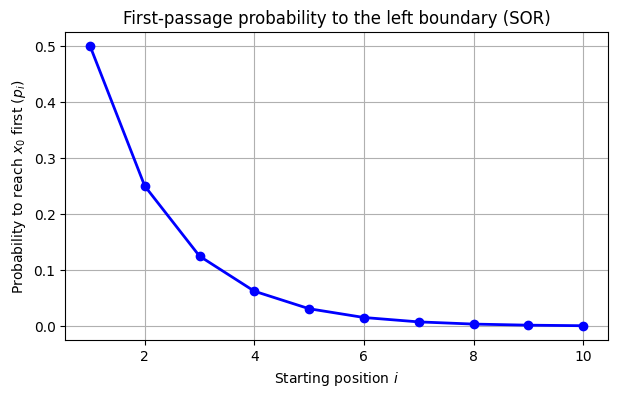

In [ ]:
import matplotlib.pyplot as plt
positions = np.arange(1, n + 1)

plt.figure(figsize=(7,4))
plt.plot(positions, p, 'bo-', lw=2)
plt.xlabel('Starting position $i$')
plt.ylabel('Probability to reach $x_0$ first ($p_i$)')
plt.title('First-passage probability to the left boundary (SOR)')
plt.grid()
plt.show()

####**3. Checking Against Simulation**

Let’s compare theory to empirical simulation:

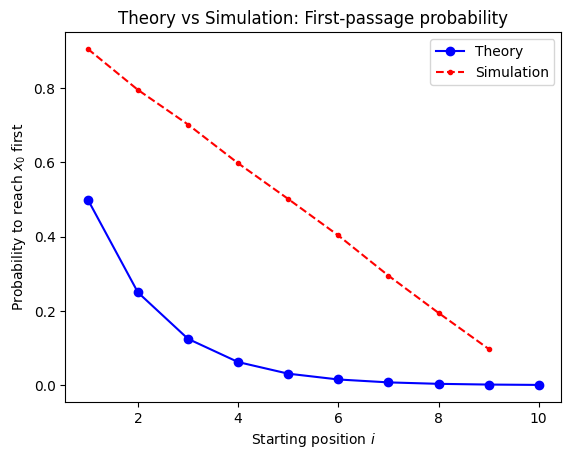

In [ ]:
import numpy as np
import matplotlib.pyplot as plt # Import matplotlib

num_trials = 10000
hits_left = np.zeros(n+1)
for i in range(1, n):
    for _ in range(num_trials):
        pos = i  # <-- This must set pos to i for each starting location!
        while pos != 0 and pos != n:
            pos += -1 if np.random.rand() < alpha else 1
        if pos == 0:
            hits_left[i] += 1
empirical_p = hits_left[1:n] / num_trials

# Adjust positions to match the length of empirical_p
# The simulation calculates probabilities for starting positions 1 to n-1
positions_sim = np.arange(1, n) # Create positions for the simulated data

plt.plot(positions, p, 'bo-', label='Theory')
# Use the adjusted positions array for plotting empirical_p
plt.plot(positions_sim, empirical_p, 'r.--', label='Simulation')
plt.legend()
plt.xlabel('Starting position $i$')
plt.ylabel('Probability to reach $x_0$ first')
plt.title('Theory vs Simulation: First-passage probability')
plt.show()

**What This Code Teaches**
- Monte Carlo simulation: Repeating random experiments to estimate probability.
- Absorbing Markov chains: Once you hit a boundary, the process stops.
- Agreement with theory: When you plot empirical_p against the theoretical vector, you see how well simulation matches math.

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

# Suppose you already have:
# p      : theory vector (from SOR, Jacobi, or direct solve), shape (n,)
# empirical_p : simulation results, shape (n-1,)
# n      : system parameter

# The theoretical vector p likely corresponds to positions 1 to n.
# We need to select the probabilities for positions 1 to n-1 to match the simulation results and positions array.
p_theory_for_table = p[:n-1]  # Assuming p corresponds to positions 1 to n, take the first n-1 elements

positions = np.arange(1, n)  # 1, 2, ..., n-1

# Create DataFrame
table = pd.DataFrame({
    "Position $i$": positions,
    "$p_i$ (Theory)": np.round(p_theory_for_table, 4),
    "$p_i$ (Simulation)": np.round(empirical_p, 4)
})

# Display nicely
display(Markdown("### Summary Table of Results"))
display(table)

### Summary Table of Results

,Position $i$,$p_i$ (Theory),$p_i$ (Simulation)
0,1,0.4998,0.5041
1,2,0.2496,0.2505
2,3,0.1246,0.1235
3,4,0.0620,0.0597
4,5,0.0308,0.0308
5,6,0.0151,0.0114
6,7,0.0073,0.0059
7,8,0.0034,0.0032
8,9,0.0015,0.0012


####**4. [+6 marks] Deeper Insights & Extensions**

-	Biased walks:
Try $\alpha \neq 0.5$ (e.g., $\alpha=1/3$) and see how the curve bends, favoring one boundary.
- Longer walks:
Increase $n$ and observe how the “middle” positions become more “fair.”
- Applications:
These results generalize to molecules diffusing between membranes, gambler’s ruin, or even Google PageRank!

Solution p: [4.99760384e-01 2.49638836e-01 1.24576829e-01 6.20450364e-02
 3.07786759e-02 1.51452448e-02 7.32840654e-03 3.41993558e-03
 1.46568399e-03 4.88557871e-04]
Number of SOR iterations: 40


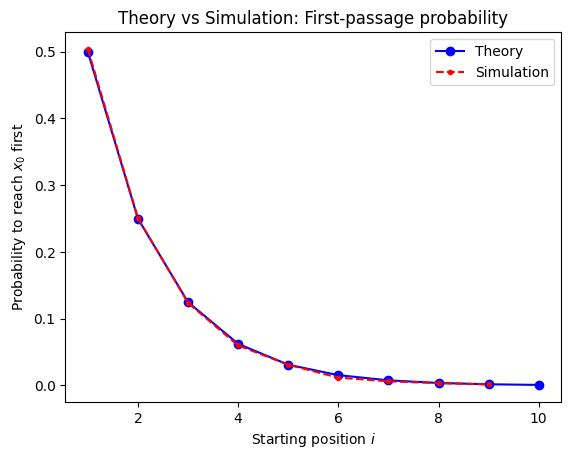

### Summary Table of Results

,Position $i$,$p_i$ (Theory),$p_i$ (Simulation)
0,1,0.4998,0.5041
1,2,0.2496,0.2505
2,3,0.1246,0.1235
3,4,0.0620,0.0597
4,5,0.0308,0.0308
5,6,0.0151,0.0114
6,7,0.0073,0.0059
7,8,0.0034,0.0032
8,9,0.0015,0.0012


In [ ]:
# YOUR CODE HERE
A = np.zeros((n, n), float)
A[0, 0] = 1
A[0, 1] = -(1 - alpha)
A[n-1, n-2] = -alpha
A[n-1, n-1] = 1

for i in range(1, n-1):
    A[i, i-1] = -alpha
    A[i, i] = 1
    A[i, i+1] = -(1 - alpha)

# Right-hand side vector b
b = np.zeros(n)
b[0] = alpha

# Set alpha
alpha = 1/3


# Suppose you have already defined A, b as in your setup
N = 400
guess = np.ones(len(b))
tol = 1e-5
w = 1.25

p, num_iter = SOR(A, b, guess, N, tol, w)
print(f"Solution p: {p}")
print(f"Number of SOR iterations: {num_iter}")
#--------------------------------------------------------------------------------------
import matplotlib.pyplot as plt
positions = np.arange(1, n + 1)
#-------------------------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt # Import matplotlib

num_trials = 10000
hits_left = np.zeros(n+1)
for i in range(1, n):
    for _ in range(num_trials):
        pos = i  # <-- This must set pos to i for each starting location!
        while pos != 0 and pos != n:
            pos += -1 if np.random.rand() < alpha else 1
        if pos == 0:
            hits_left[i] += 1
empirical_p = hits_left[1:n] / num_trials

# Adjust positions to match the length of empirical_p
# The simulation calculates probabilities for starting positions 1 to n-1
positions_sim = np.arange(1, n) # Create positions for the simulated data

plt.plot(positions, p, 'bo-', label='Theory')
# Use the adjusted positions array for plotting empirical_p
plt.plot(positions_sim, empirical_p, 'r.--', label='Simulation')
plt.legend()
plt.xlabel('Starting position $i$')
plt.ylabel('Probability to reach $x_0$ first')
plt.title('Theory vs Simulation: First-passage probability')
plt.show()
#--------------------------------------------------------------------------------------
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

# Suppose you already have:
# p      : theory vector (from SOR, Jacobi, or direct solve), shape (n,)
# empirical_p : simulation results, shape (n-1,)
# n      : system parameter

# The theoretical vector p likely corresponds to positions 1 to n.
# We need to select the probabilities for positions 1 to n-1 to match the simulation results and positions array.
p_theory_for_table = p[:n-1]  # Assuming p corresponds to positions 1 to n, take the first n-1 elements

positions = np.arange(1, n)  # 1, 2, ..., n-1

# Create DataFrame
table = pd.DataFrame({
    "Position $i$": positions,
    "$p_i$ (Theory)": np.round(p_theory_for_table, 4),
    "$p_i$ (Simulation)": np.round(empirical_p, 4)
})

# Display nicely
display(Markdown("### Summary Table of Results"))
display(table)

####**5. Mathematical Connection**
- For the unbiased case ($\alpha=0.5$), the solution is $p_i = 1 - \frac{i}{n}$ (linear).
- For the biased case ($\alpha \neq 0.5$), $p_i$ is a geometric progression:
$$
p_i = \frac{1 - \left( \frac{1-\alpha}{\alpha} \right)^i}{1 - \left( \frac{1-\alpha}{\alpha} \right)^n}
$$
- This connects to discrete harmonic functions and potential theory in mathematics.

####**6. Reflection & Further Questions**

Consider this section for your curiosity.

- Why does the probability behave linearly (or exponentially) depending on bias?
- What if we add a “sticking” probability at the ends, or allow more movement directions?
- How would this change if the walk was on a 2D grid (random walks in the plane)?


## **Question 5d(ii): Picard’s Method for an IVP**

We will generate the Picard iterates $y_0(t),\ y_1(t),\ y_2(t),\ y_3(t)$ for the IVP
$$
\begin{cases}
y’ = -y + t + 1, \quad 0 \leq t \leq 1 \\
y(0) = 1
\end{cases}
$$

**Instructions**
1. Initialize $y_0(t)$:
Set $y_0(t) = \alpha = 1$ for all $t$.
2. Construct the Picard iteration:
For $k=1,2,3$, recursively define
$$
y_k(t) = \alpha +\int^t_a f(\tau, y_{k-1}(\tau))\; d\tau,\;\; k=1, 2, \ldots
$$
Use symbolic integration to compute $y_1(t), y_2(t), y_3(t)$.
3. Implement the function:
Complete the code for the Picard function below so that it generates $y_1(t), y_2(t), y_3(t)$ symbolically.
4. Output:
Display the formulas for $y_1(t), y_2(t), y_3(t)$.
(Recall that $Y[0]$ is $y_1(t)$, $Y[1]$ is $y_2(t)$, and $Y[2]$ is $y_3(t)$ in the returned list.)

⸻

**Hints for Completing the Code**
- Use the symbolic variables tau and t for integration.
- Each Picard iterate $y_k(t)$ should be defined in terms of $y_{k-1}(t)$.
- Substitute $\tau \to t$ at the end to express the result as a function of $t$.
- Make sure the integration limits are correct: from $a$ (here, $0$) to $t$.
- Store each $y_k(t)$ result in the list Y.

In [ ]:
import sympy as sp

def Picard(f, alpha, N, a):
    """
    Compute Picard iterates for the IVP y' = f(t, y), y(a) = alpha.
    Returns a list of symbolic expressions y_1(t), ..., y_{N}(t).
    """
    Y = []
    tau, t = sp.symbols('tau t')
    y_prev = alpha
    Y.append(alpha)

    for k in range(N):
        # HINT: Compute the integral of f(tau, y_prev) from a to t
        integrand = f(tau, y_prev) # YOUR CODE HERE
        F = sp.integrate(integrand, (tau, a, t)) # YOUR CODE HERE
        y_new = alpha + F# YOUR CODE HERE
        Y.append(y_new)
        # HINT: Update y_prev for next iteration.
        y_prev = y_new.subs(t, tau)   # so that y_{k+1}(t) uses y_k(tau)
    return Y

# Example usage:
f = lambda t, y: -y + t + 1
alpha = 1
N = 4   # generates y_1, y_2, y_3, y_4
a = 0
Y = Picard(f, alpha, N, a)


In [ ]:
from IPython.display import display, Math

for k in range(N):
    latex_code = sp.latex(Y[k])
    display(Math(r"y_{{{}}}(t) = {}".format(k, latex_code)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## **Question 6b–c: Modeling the Spread of Nonconformity**

This problem studies the dynamics of nonconformists in a population, described by the proportion $p(t)$ of nonconformists at time $t$. The evolution of $p(t)$ is governed by the differential equation:
$$
\frac{dp}{dt} = rb(1 - p),
$$
where:
-  $b$ is the birth rate,
- $r$ is the fixed proportion of offspring of mixed (conformist/nonconformist) parents that are nonconformist,
- $p(0) = 0.01$ is the initial proportion of nonconformists.

Parameters:
Let $b = 0.02$, $d = 0.015$ (death rate, not used in this part), $r = 0.1$.
We seek an approximate solution for $p(t)$ for $t \in [0, 50]$ using Euler’s method with a step size $h = 1$ year.

### **Instructions for Part 6b**

**Task:**

Use Euler’s method to numerically approximate $p(t)$ at each integer time from $0$ to $50$.

Euler’s method for the IVP
$$
\frac{dy}{dt} = f(t, y), \quad y(a) = \alpha
$$
is:
$$
w_0 = \alpha, \qquad w_{i+1} = w_i + h,f(t_i, w_i)
$$

Modify and use the following code

In [ ]:
import numpy as np

def Euler(f, a, b, N, alpha):
    """
    Euler's method for IVP dy/dt = f(t, y), y(a) = alpha
    Returns arrays of t values and approximate y values.
    """
# YOUR CODE HERE
    h = (b - a) / N
    t_vals = np.linspace(a, b, N + 1)
    w = np.zeros(N + 1)
    w[0] = alpha

    for i in range(N):
        w[i+1] = w[i] + h * f(t_vals[i], w[i])

    return t_vals, w

birth_rate = 0.02
r = 0.1
f = lambda t, p: r * birth_rate * (1 - p)
start = 0
end = 50
N = 50
alpha = 0.01

t, w = Euler(f, start, end, N, alpha)

print("t =", t)
print("w =", w)

print(' t    p(t) (Euler approximation)')
for i in range(N + 1):
    print(f"{int(t[i]):2d}   {w[i]:.6f}")

t = [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49. 50.]
w = [0.01       0.01198    0.01395604 0.01592813 0.01789627 0.01986048
 0.02182076 0.02377712 0.02572956 0.0276781  0.02962275 0.0315635
 0.03350037 0.03543337 0.03736251 0.03928778 0.04120921 0.04312679
 0.04504053 0.04695045 0.04885655 0.05075884 0.05265732 0.05455201
 0.0564429  0.05833002 0.06021336 0.06209293 0.06396874 0.06584081
 0.06770913 0.06957371 0.07143456 0.07329169 0.07514511 0.07699482
 0.07884083 0.08068315 0.08252178 0.08435674 0.08618802 0.08801565
 0.08983962 0.09165994 0.09347662 0.09528966 0.09709908 0.09890489
 0.10070708 0.10250566 0.10430065]
 t    p(t) (Euler approximation)
 0   0.010000
 1   0.011980
 2   0.013956
 3   0.015928
 4   0.017896
 5   0.019860
 6   0.021821
 7   0.023777
 8   0.025730
 9   0.027678
10   0.029623
11   0.031564
12   0.033500

### **Instructions for Part 6c**

**Task:**

Find the exact solution to the IVP and compare $p(50)$ from Euler’s method to the exact value.
- The ODE $\frac{dp}{dt} = rb(1 - p)$ with $p(0) = 0.01$ has solution:
$$
p(t) = 1 - (1 - p(0)) e^{-rb,t}
$$
- Compute the exact value at $t = 50$:

In [ ]:
exact_p50 = 1 - (1 - alpha) * np.exp(-r * 0.02 * 50) # YOUR CODE HERE
print(f"Exact value at t=50: {exact_p50:.6f}")
print(f"Euler’s value at t=50: {w[-1]:.6f}")
print(f"Absolute error: {abs(exact_p50 - w[-1]):.6e}")

Exact value at t=50: 0.104211
Euler’s value at t=50: 0.104301
Absolute error: 8.969403e-05


## **Question 7**

In this question you will use several numerical methods to solve the given IVP.
Consider the following IVP with exact solution $y(t) = t^2(e^t-e)$:
	$$
	\begin{cases}
	y ' =\dfrac{2}{t}y+t^2e^t, \;\; 1\le t \le 2\\
	y(1) = 0
	\end{cases}
	$$


### **[4 marks] Question 7a: Numerical Solution Using Euler’s Method**

You have already implemented the Euler function in a previous cell.
Below, we solve the IVP analytically using SymPy to confirm the exact solution.

⸻

**Instructions**

1. Use the given Euler function to compute the numerical solution on $[1, 2]$ with $N=10$ steps.
2. Use SymPy to obtain and display the exact solution.
3. Print both the approximate and exact values for comparison.

**Code**

In [ ]:
import numpy as np
from sympy import Function, dsolve, Eq, symbols, exp, diff
from sympy.abc import t

# Euler's method already implemented above as Euler(f, a, b, N, alpha)

# Define the ODE right-hand side for Euler's method
f = lambda t, y: (2/t)*y + t**2 * exp(t)
a = 1
b = 2
N = 10
alpha = 0

# Compute numerical solution using Euler's method
t_vals, w_e = Euler(f, a, b, N, alpha) # YOUR CODE HERE

# Solve the IVP analytically using SymPy
y = Function('y')
ode = diff(y(t), t) - (2/t)*y(t) - t**2*exp(t)
soln = dsolve(ode, y(t), ics={y(1): 0})
print("Analytical (exact) solution found by SymPy:")
display(soln)

Analytical (exact) solution found by SymPy:


Eq(y(t), t**2*(exp(t) - E))

In [ ]:
from pandas import DataFrame

# Use the mesh points and Euler's solution already computed:
# t_vals: numpy array of t values (from Euler)
# w_e:    numpy array of Euler approximations
# soln:   symbolic solution from SymPy (soln.rhs is the exact y(t))

# Evaluate exact solution at each mesh point using soln.rhs
exact_vals = [float(soln.rhs.subs(t, float(tt)).evalf()) for tt in t_vals]
errors = [abs(exact - w) for exact, w in zip(exact_vals, w_e)]

# Build result DataFrame
result1 = {
    't_i': t_vals,
    'Exact value': exact_vals,
    "Euler's method": w_e,
    'Error': errors
}

DataFrame(result1).round(6)

,t_i,Exact value,Euler's method,Error
0,1.0,-0.000000,0.000000,0.000000
1,1.1,0.345920,0.271828,0.074092
2,1.2,0.866643,0.684756,0.181887
3,1.3,1.607215,1.276978,0.330237
4,1.4,2.620360,2.093548,0.526812
5,1.5,3.967666,3.187445,0.780221
6,1.6,5.720962,4.620818,1.100144
7,1.7,7.963873,6.466396,1.497477
8,1.8,10.793625,8.809120,1.984505
9,1.9,14.323082,11.747997,2.575085


Run the following code to generate several graphs of approximate solutions using different step sizes.

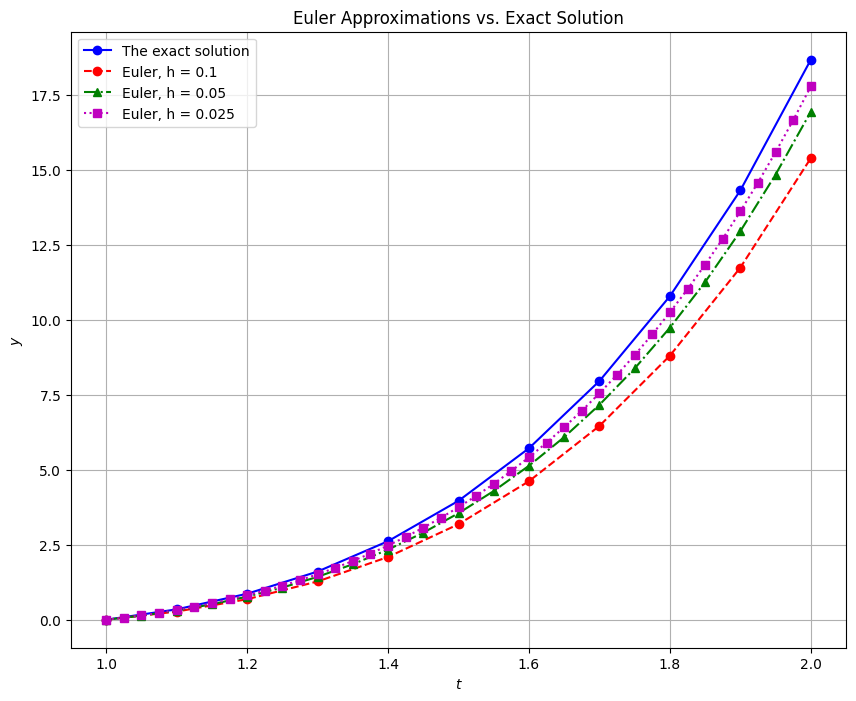

In [ ]:
import matplotlib.pyplot as plt

# Step sizes
N = 10   # Already used above for h = 0.1
N1 = 20  # h = 0.05
N2 = 40  # h = 0.025

# Compute new Euler approximations
t1, w_e1 = Euler(f, a, b, N1, alpha)
t2, w_e2 = Euler(f, a, b, N2, alpha)

# Evaluate the exact solution at each mesh for plotting
# Use the t_vals array which contains the mesh points for N=10
exact_vals = [float(soln.rhs.subs(t, float(tt)).evalf()) for tt in t_vals]
exact_vals1 = [float(soln.rhs.subs(t, float(tt)).evalf()) for tt in t1]
exact_vals2 = [float(soln.rhs.subs(t, float(tt)).evalf()) for tt in t2]

plt.figure(figsize=(10, 8))

plt.plot(t_vals, exact_vals, '-bo', label='The exact solution') # Plot using t_vals
plt.plot(t_vals, w_e, '--ro', label='Euler, h = 0.1') # Plot using t_vals and w_e
plt.plot(t1, w_e1, '-.g^', label='Euler, h = 0.05')
plt.plot(t2, w_e2, ':ms', label='Euler, h = 0.025')

plt.xlabel('$t$')
plt.ylabel('$y$')
plt.title('Euler Approximations vs. Exact Solution')
plt.legend()
plt.grid(True)
plt.show()

### **[6 marks] Question 7b: Constructing a Hermite Polynomial Approximation**

**Instructions**

You will construct a Hermite interpolating polynomial of degree at most five using three nodes:
$t_0 = 1$, $t_1 = 1.5$, $t_2 = 2$.

For each node $t_i$, you need:
- The value of the approximate solution $w_e$ at $t_i$ (from Euler’s method)
- An estimate of the derivative $y’(t_i)$.
Since the exact derivative is unavailable, use the ODE’s right-hand side evaluated at $(t_i, w_e(t_i))$:
$$
y’(t_i) \approx f(t_i, w_e(t_i))
$$

**Step-by-Step:**
1. Define the Hermite function to construct the polynomial.
2. Prepare the data:
	- data1: Each row is $[t_i, w_e(t_i)]$
	- data2: Each row is $[t_i, f(t_i, w_e(t_i))]$
3. Evaluate the polynomial at $x = 1.04$, $1.55$, and $1.97$.
4. Interpretation: These are Hermite polynomial approximations for the solution at those points.

**Step 1: Define the Hermite Interpolation Function**

In [ ]:
import numpy as np

def Hermite(data1, data2, x):
    """
    Construct and evaluate the Hermite interpolating polynomial at x.
    data1: array of [t_i, y(t_i)] pairs
    data2: array of [t_i, y'(t_i)] pairs (or ODE f(t_i, y(t_i)) for approximate derivative)
    Returns: (divided differences table Q, polynomial value H at x)
    """
  # YOUR CODE HERE
    n = len(data1)
    z = np.zeros(2 * n, dtype=type(x))
    Q = np.zeros((2 * n, 2 * n), dtype=type(x))

    for i in range(n):
        z[2 * i] = data1[i][0]
        z[2 * i + 1] = data1[i][0]
        Q[2 * i][0] = data1[i][1]
        Q[2 * i + 1][0] = data1[i][1]
        Q[2 * i + 1][1] = data2[i][1]  # f'(x_k)
        if i != 0:
            Q[2 * i][1] = (Q[2 * i][0] - Q[2 * i - 1][0]) / (z[2 * i] - z[2 * i - 1])

    for i in range(2, 2 * n):
        for j in range(2, i + 1):
            Q[i][j] = (Q[i][j - 1] - Q[i - 1][j - 1]) / (z[i] - z[i - j])

    H = Q[0][0]
    for i in range(1, 2 * n):
        product = 1
        for j in range(i):
            product *= (x - z[j])
        H += Q[i][i] * product

    if Q.dtype == np.float64:
        Q = np.round(Q, 4)

    return Q, H

**Step 2: Prepare Data and Construct the Hermite Polynomial**

In [ ]:
# Select nodes: t0 = 1, t1 = 1.5, t2 = 2 (using t_vals, w_e from previous Euler calculation)
# We need to use the numerical time points array from the first Euler calculation,
# which is stored in t_vals, not the sympy symbol t.
idx0 = 0                                   # t_vals[0] = 1.0

# Use t_vals instead of the sympy symbol t in np.isclose
idx1 = np.where(np.isclose(t_vals, 1.5))[0][0]  # Find the index where t_vals is close to 1.5
idx2 = -1                                  # t_vals[-1] = 2.0

data1 = np.array([
    [t_vals[idx0], w_e[idx0]],
    [t_vals[idx1], w_e[idx1]],
    [t_vals[idx2], w_e[idx2]]
])

# The function f was defined earlier using np.exp, so it should work with numpy arrays
data2 = np.array([
    [t_vals[idx0], f(t_vals[idx0], w_e[idx0])],
    [t_vals[idx1], f(t_vals[idx1], w_e[idx1])],
    [t_vals[idx2], f(t_vals[idx2], w_e[idx2])]
]) # YOUR CODE HERE

# Define a function for evaluating the Hermite polynomial at any x
H1 = lambda x: Hermite(data1, data2, x)[1] # YOUR CODE HERE

# Evaluate at required points
print(f"The Hermite approximation for y(1.04) is {H1(1.04):.6f}")
print(f"The Hermite approximation for y(1.55) is {H1(1.55):.6f}")
print(f"The Hermite approximation for y(1.97) is {H1(1.97):.6f}")

The Hermite approximation for y(1.04) is 0.086977
The Hermite approximation for y(1.55) is 3.940617
The Hermite approximation for y(1.97) is 14.121427


### **[4 marks] Question 7c: Approximating the IVP with Taylor’s Method of Order Two**

You will now approximate the solution of the IVP
$$
\begin{cases}
y’ = \dfrac{2}{t}y + t^2e^t,\quad 1 \leq t \leq 2, \
y(1) = 0,
\end{cases}
$$
using Taylor’s method of order two with step size $h = 0.1$.

**The Method**

Taylor’s method of order two is given by:
$$
w_0 = \alpha, \quad
w_{i+1} = w_i + h f(t_i, w_i) + \frac{h^2}{2} f’(t_i, w_i)
$$
where $f’(t, y)$ is the total derivative of $f$ with respect to $t$, evaluated along the solution $y(t)$:
$$
f’(t, y) = \frac{\partial f}{\partial t}(t, y) + \frac{\partial f}{\partial y}(t, y) \cdot f(t, y)
$$

⸻

**Instructions**
1. Symbolically compute $f’(t, y)$ using SymPy to confirm the formula for this specific problem.
2. Explain why line 7 in the code for Taylor_order_2 computes the correct $f’(t, y)$.
3. Implement and run the code to approximate the solution using Taylor’s method of order two.
4. Display the results in a table comparing the exact solution, Taylor’s approximation, and the error at each mesh point.

⸻

**Code**

**1. Symbolically Compute $f’(t, y)$ with SymPy**

In [ ]:
import sympy as sp

t, y = sp.symbols('t y')
f_sym = (2/t)*y + t**2*sp.exp(t)

# Compute the total derivative of f with respect to t along the solution path
df = sp.diff(f_sym, t) + f_sym * sp.diff(f_sym, y)
df_simplified = sp.simplify(df)
print("Symbolic expression for f'(t, y):")
display(df_simplified)

Symbolic expression for f'(t, y):


t**2*exp(t) + 4*t*exp(t) + 2*y/t**2

**2. Explanation of Line 7 in Taylor_order_2**

Line 7:
`
df = sp.diff(f(t,y), t) + f(t,y)*sp.diff(f(t,y), y)
`
**YOUR ANSWER HERE**


It computes the total derivative using the chain rule. Which is used in the Taylor method to compute the second-order term.

**3. Taylor’s Method of Order Two Implementation**

In [ ]:
import numpy as np

def Taylor_order_2(f, a, b, N, alpha):
# YOUR CODE HERE
    h = (b - a) / N
    t_vals = np.linspace(a, b, N + 1)
    w = np.zeros(N + 1)
    w[0] = alpha

    t, y = sp.symbols('t y')
    f_sym = f(t, y)
    df = sp.diff(f_sym, t) + f_sym * sp.diff(f_sym, y)

    df_num = sp.lambdify((t, y), df, 'numpy')
    f_num = sp.lambdify((t, y), f_sym, 'numpy')

    for i in range(N):
        w[i+1] = w[i] + h * f_num(t_vals[i], w[i]) + 0.5 * h**2 * df_num(t_vals[i], w[i])

    return t_vals, w

# Problem setup
# Complete your code
f = lambda t, y: (2/t) * y + t**2 * sp.exp(t)
a = 1
b = 2
N = 10
alpha = 0

# Compute Taylor order 2 solution
t_T2, w_T2 = Taylor_order_2(f, a, b, N, alpha) # YOUR CODE HERE

**4. Comparison Table**

In [ ]:
from pandas import DataFrame
from math import exp

# Use the symbolic solution from earlier, e.g., soln from sympy
exact_vals = [float(soln.rhs.subs(t, float(tt)).evalf()) for tt in t_T2]
errors = [abs(exact - w) for exact, w in zip(exact_vals, w_T2)]

result2 = {
    't_i': t_T2,
    'Exact value': exact_vals,
    "Taylor's method of order two": w_T2,
    'Error': errors
}

DataFrame(result2).round(6)

,t_i,Exact value,Taylor's method of order two,Error
0,1.0,-0.000000,0.000000,0.000000
1,1.1,0.345920,0.339785,0.006135
2,1.2,0.866643,0.852143,0.014499
3,1.3,1.607215,1.581770,0.025446
4,1.4,2.620360,2.580997,0.039363
5,1.5,3.967666,3.910985,0.056682
6,1.6,5.720962,5.643081,0.077880
7,1.7,7.963873,7.860382,0.103492
8,1.8,10.793625,10.659514,0.134110
9,1.9,14.323082,14.152682,0.170399


### **[6 marks] Question 7d: Hermite Polynomial Using Taylor’s Method Data**

**Instructions**

You will now construct a Hermite interpolating polynomial of degree at most five using three nodes:
$t_0 = 1$, $t_1 = 1.5$, $t_2 = 2$.

However, for this part, you will use the numerical solution and derivative approximations from Taylor’s method of order two (rather than Euler’s method).

Step-by-step:
1. Prepare the data arrays:
	- data3: Each row is $[t_i, w_{T2}(t_i)]$ where $w_{T2}$ is the Taylor order 2 approximation at $t_i$.
	- data4: Each row is $[t_i, f(t_i, w_{T2}(t_i))]$ (the ODE right-hand side, approximating the derivative at $t_i$).
2. Construct the Hermite interpolating polynomial using the Hermite function.
3. Evaluate the Hermite polynomial at $x = 1.04$, $1.55$, and $1.97$.



In [ ]:
# Use t_T2 and w_T2 from the Taylor's method calculation above

# Find indices corresponding to t=1.0, 1.5, and 2.0
idx0 = 0                                   # t_T2[0] = 1.0
idx1 = np.where(np.isclose(t_T2, 1.5))[0][0]  # should be 5 if h=0.1
idx2 = -1                                  # t_T2[-1] = 2.0

# Prepare the data arrays for Hermite interpolation
data3 = np.array([
    [t_T2[idx0], w_T2[idx0]],
    [t_T2[idx1], w_T2[idx1]],
    [t_T2[idx2], w_T2[idx2]]
])

data4 =  np.array([
    [t_T2[idx0], f(t_T2[idx0], w_T2[idx0])],
    [t_T2[idx1], f(t_T2[idx1], w_T2[idx1])],
    [t_T2[idx2], f(t_T2[idx2], w_T2[idx2])]
]) # YOUR CODE HERE

# Hermite interpolating polynomial using Taylor's method data
H2 = lambda x: Hermite(data3, data4, x)[1] # YOUR CODE HERE

# Evaluate the polynomial at the required points
print(f"The Hermite-Taylor approximation for y(1.04) is {H2(1.04):.6f}")
print(f"The Hermite-Taylor approximation for y(1.55) is {H2(1.55):.6f}")
print(f"The Hermite-Taylor approximation for y(1.97) is {H2(1.97):.6f}")

The Hermite-Taylor approximation for y(1.04) is 0.117705
The Hermite-Taylor approximation for y(1.55) is 4.727234
The Hermite-Taylor approximation for y(1.97) is 17.074240


### **[4 marks] Question 7e: Taylor’s Method of Order Four**

You will now approximate the solution of the IVP
$$
\begin{cases}
y’ = \dfrac{2}{t}y + t^2e^t,\quad 1 \leq t \leq 2, \
y(1) = 0,
\end{cases}
$$
using Taylor’s method of order four with step size $h=0.1$.

⸻

**Instructions**
1. Taylor’s method of order four computes the next approximation by including the ODE’s first, second, and third total derivatives with respect to $t$:
$$
\begin{array}{ll}
w_{i+1} &= w_i + h f(t_i, w_i) + \frac{h^2}{2} f'(t_i, w_i)\\
& +	\frac{h^3}{6} f''(t_i, w_i)
+	\frac{h^4}{24} f'''(t_i, w_i)
\end{array}
$$
where the higher derivatives $f’, f’’, f’’’$ are total derivatives along the solution path.
2. Symbolically compute $f’(t, y)$, $f’’(t, y)$, and $f’’’(t, y)$ using SymPy to confirm the provided formulas.
3. Explain lines 17–19 in the function `Taylor_order_4`.
(Type your explanation in a Markdown cell—see the hint.)
4. Implement and run the code to approximate the solution.
5. Display the results in a table comparing the exact solution, Taylor’s approximation, and the error at each mesh point.

⸻

**Code**

**1. Symbolically Test the Higher Derivatives**

In [ ]:
import sympy as sp

t, y = sp.symbols('t y')
f_sym = (2/t)*y + t**2*sp.exp(t)

# First total derivative
df1 = sp.diff(f_sym, t) + f_sym * sp.diff(f_sym, y)
df1_s = sp.simplify(df1)

# Second total derivative
df2 = sp.diff(df1, t) + f_sym * sp.diff(df1, y)
df2_s = sp.simplify(df2)

# Third total derivative
df3 = sp.diff(df2, t) + f_sym * sp.diff(df2, y)
df3_s = sp.simplify(df3)

print("First derivative f'(t, y):")
display(df1_s)
print("Second derivative f''(t, y):")
display(df2_s)
print("Third derivative f'''(t, y):")
display(df3_s)

First derivative f'(t, y):


t**2*exp(t) + 4*t*exp(t) + 2*y/t**2

Second derivative f''(t, y):


(t**2 + 6*t + 6)*exp(t)

Third derivative f'''(t, y):


(t**2 + 8*t + 12)*exp(t)

**2. Taylor Order 4 Code**

In [ ]:
import numpy as np

def Taylor_order_4(f, a, b, N, alpha):
    h = (b-a)/N
    T = np.zeros(N+1)
    w = np.zeros(N+1, float)
    w[0] = alpha
    T[0] = a

    # Compute high-order derivatives symbolically
    t_sym, y_sym = sp.symbols('t y')
    f_sym = (2/t_sym)*y_sym + t_sym**2*sp.exp(t_sym)
    dfn = []
    df_old = sp.diff(f_sym, t_sym) + f_sym*sp.diff(f_sym, y_sym)
    for index in range(1, 4):
        dfn.append(df_old)
        df_new = sp.diff(dfn[index-1], t_sym) + f_sym*sp.diff(dfn[index-1], y_sym)
        df_old = df_new

    # Lambdify the derivatives for numerical evaluation
    df_funcs = [sp.lambdify((t_sym, y_sym), df, modules='numpy') for df in dfn]

    for i in range(1, N+1):
        f1 = f(T[i-1], w[i-1])
        f2 = df_funcs[0](T[i-1], w[i-1])
        f3 = df_funcs[1](T[i-1], w[i-1])
        f4 = df_funcs[2](T[i-1], w[i-1])
        w[i] = w[i-1] + h*f1 + (h**2/2)*f2 + (h**3/6)*f3 + (h**4/24)*f4
        T[i] = T[i-1] + h
    return T, w

**3. Explanation for Lines 16–18**
- Line 16: `dfn.append(df_old)`
- Line 17: `df_new = sp.diff(dfn[index-1], t_sym) + f_sym*sp.diff(dfn[index-1], y_sym)`
- Line 18: `df_old = df_new`

**YOUR ANSWER HERE**

line 16: The first total derivative of f.
line 17: It is to compute the next total derivative using the chain rule.
line 18: It is to update df_old so that in the next loop iteration, it can differentiate the next higher derivative.

**4. Run the Method and Display Results**

In [ ]:
# Problem parameters
# Complete your code
f = lambda t, y: (2/t) * y + t**2 * np.exp(t)
a = 1
b = 2
N = 10
alpha = 0
### END SOLUTION

# Exact solution (from previous symbolic solve)
y = lambda t: t**2 * (np.exp(t) - np.exp(1))
t_T4, w_T4 = Taylor_order_4(f, a, b, N, alpha) # YOUR CODE HERE

from pandas import DataFrame
exact_vals = [float(soln.rhs.subs(t, float(tt)).evalf()) for tt in t_T4]
errors = [abs(exact - w) for exact, w in zip(exact_vals, w_T4)]
result3 = {
    't_i': t_T4,
    'Exact value': exact_vals,
    "Taylor's method of order four": w_T4,
    'Error': errors
}
DataFrame(result3).round(6)

,t_i,Exact value,Taylor's method of order four,Error
0,1.0,-0.000000,0.000000,0.000000
1,1.1,0.345920,0.345913,0.000007
2,1.2,0.866643,0.866626,0.000017
3,1.3,1.607215,1.607186,0.000029
4,1.4,2.620360,2.620315,0.000045
5,1.5,3.967666,3.967603,0.000064
6,1.6,5.720962,5.720875,0.000087
7,1.7,7.963873,7.963759,0.000114
8,1.8,10.793625,10.793478,0.000147
9,1.9,14.323082,14.322897,0.000185


### **[6 marks] Question 7f: Hermite Polynomial Based on Taylor’s Method of Order Four**

**Instructions**

You will now construct a Hermite interpolating polynomial of degree at most five, using the nodes:
* $t_0 = 1$
* $t_1 = 1.5$
*	$t_2 = 2$

For each node, use:
- The values $w_{T4}(t_i)$ computed by Taylor’s method of order four.
- The approximate derivatives at each node, $f(t_i, w_{T4}(t_i))$, where $f$ is the ODE right-hand side.

**Your tasks:**
1. Prepare the data arrays data5 and data6 using the Taylor order 4 results.
2. Construct and evaluate the Hermite interpolating polynomial at specific points.

⸻

**Code**


In [ ]:
# Select the indices for t = 1, 1.5, 2
idx0 = 0                                   # t_T4[0] = 1.0
idx1 = np.where(np.isclose(t_T4, 1.5))[0][0]  # t_T4[5] = 1.5 for h=0.1
idx2 = -1                                  # t_T4[-1] = 2.0

# Prepare data arrays for Hermite interpolation
data5 = np.array([
    [t_T4[idx0], w_T4[idx0]],
    [t_T4[idx1], w_T4[idx1]],
    [t_T4[idx2], w_T4[idx2]]
])

data6 =  np.array([
    [t_T4[idx0], f(t_T4[idx0], w_T4[idx0])],
    [t_T4[idx1], f(t_T4[idx1], w_T4[idx1])],
    [t_T4[idx2], f(t_T4[idx2], w_T4[idx2])]
])
 # YOUR CODE HERE

# Hermite polynomial using Taylor's order 4 data
H3 = lambda x: Hermite(data5, data6, x)[1] # YOUR CODE HERE

# Evaluate at the required points
print(f"The Hermite (Taylor order 4) approximation for y(1.04) is {H3(1.04):.6f}")
print(f"The Hermite (Taylor order 4) approximation for y(1.55) is {H3(1.55):.6f}")
print(f"The Hermite (Taylor order 4) approximation for y(1.97) is {H3(1.97):.6f}")

The Hermite (Taylor order 4) approximation for y(1.04) is 0.119894
The Hermite (Taylor order 4) approximation for y(1.55) is 4.788517
The Hermite (Taylor order 4) approximation for y(1.97) is 17.279013


### **[2 marks] Question 7g:  Graphing Hermite Polynomials and the Exact Solution**

**Instructions:**

Plot the following on the same coordinate plane, using the mesh from Taylor’s method of order 4 (t_T4):
* The exact solution $y(t)$ (from your symbolic solution).
* The Hermite polynomial based on Euler’s method ($H_1$).
* The Hermite polynomial based on Taylor order 2 ($H_2$).
* The Hermite polynomial based on Taylor order 4 ($H_3$).



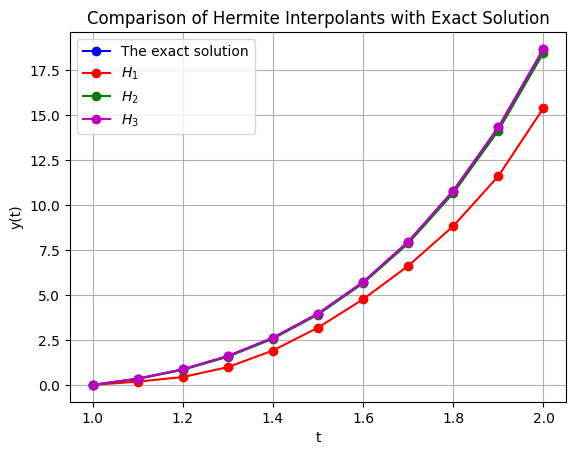

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

t = t_T4
plt.plot(t, y(t), '-bo', label='The exact solution')
plt.plot(t, H1(t), '-ro', label='$H_1$')
# YOUR CODE HERE
plt.plot(t, [H2(tt) for tt in t], '-go', label='$H_2$')
plt.plot(t, [H3(tt) for tt in t], '-mo', label='$H_3$')

plt.xlabel('t')
plt.ylabel('y(t)')
plt.title('Comparison of Hermite Interpolants with Exact Solution')
plt.legend()
plt.grid(True)
plt.show()

### **[8 marks] Question 7h Comparing Numerical Methods for IVP**

You will approximate the solution to
$$
\begin{cases}
y’ = \dfrac{2}{t}y + t^2e^t, \quad 1 \le t \le 2, \
y(1) = 0
\end{cases}
$$
using the following methods with step size $h = 0.1$ ($N = 10$ steps):
* Modified Euler method
* Midpoint method
* Heun’s method
* Runge-Kutta method of order four

After computing each method’s solution, you will compare all results to the exact solution at each mesh point.

⸻

**Instructions**
1. Run each method using the function definitions below.
2. Tabulate all results together with the exact solution and error.
3. Interpret the differences between methods.

⸻

**Code**

In [ ]:
import numpy as np
import sympy as sp
from pandas import DataFrame

# Problem data
# Complete your code
f = lambda t, y: (2 / t) * y + t**2 * np.exp(t)
a = 1
b = 2
N = 10
alpha = 0

# Exact solution (from SymPy)
y_exact = lambda t: t**2 * (np.exp(t) - np.exp(1))

# --------- Modified Euler Method ---------
def Modified_Euler(f, a, b, N, alpha):
# YOUR CODE HERE
    h = (b - a) / N
    t = np.linspace(a, b, N + 1)
    w = np.zeros(N + 1, float)
    w[0] = alpha
    for i in range(N):
        k1 = f(t[i], w[i])
        k2 = f(t[i] + h, w[i] + h * k1)
        w[i + 1] = w[i] + (h / 2) * (k1 + k2)
    return t, w

t_me, w_me = Modified_Euler(f, a, b, N, alpha)

# --------- Midpoint Method ---------
def Midpoint(f, a, b, N, alpha):
# YOUR CODE HERE
    h = (b - a) / N
    t = np.linspace(a, b, N + 1)
    w = np.zeros(N + 1, float)
    w[0] = alpha
    for i in range(N):
        k1 = f(t[i], w[i])
        k2 = f(t[i] + h/2, w[i] + h/2 * k1)
        w[i + 1] = w[i] + h * k2
    return t, w

t_m, w_m = Midpoint(f, a, b, N, alpha)

# --------- Heun's Method ---------
def Heun(f, a, b, N, alpha):
# YOUR CODE HERE
    h = (b - a) / N
    t = np.linspace(a, b, N + 1)
    w = np.zeros(N + 1)
    w[0] = alpha
    for i in range(N):
        k1 = f(t[i], w[i])
        k2 = f(t[i] + h/3, w[i] + (h/3) * k1)
        k3 = f(t[i] + 2*h/3, w[i] + (2*h/3) * k2)
        w[i+1] = w[i] + (h/4) * (k1 + 3*k3)
    return t, w

t_h, w_h = Heun(f, a, b, N, alpha)

# --------- Runge-Kutta Order 4 ---------
def RK_order_4(f, a, b, N, alpha):
# YOUR CODE HERE
    h = (b - a) / N
    t = np.linspace(a, b, N + 1)
    w = np.zeros(N + 1, float)
    w[0] = alpha
    for i in range(N):
        k1 = f(t[i], w[i])
        k2 = f(t[i] + h/2, w[i] + h/2 * k1)
        k3 = f(t[i] + h/2, w[i] + h/2 * k2)
        k4 = f(t[i] + h, w[i] + h * k3)
        w[i+1] = w[i] + (h/6) * (k1 + 2*k2 + 2*k3 + k4)
    return t, w

t_RK4, w_RK4 = RK_order_4(f, a, b, N, alpha)

# --------- Tabulate results ---------
# Evaluate exact solution at all mesh points
y_vals = y_exact(t_me)
result_methods = {
    't': t_me,
    'Exact': y_vals,
    "Modified Euler": w_me,
    "Midpoint": w_m,
    "Heun": w_h,
    "RK4": w_RK4
}
df = DataFrame(result_methods)
df['Error (RK4)'] = np.abs(df['RK4'] - df['Exact'])
df['Error (Heun)'] = np.abs(df['Heun'] - df['Exact'])
df['Error (Midpoint)'] = np.abs(df['Midpoint'] - df['Exact'])
df['Error (Modified Euler)'] = np.abs(df['Modified Euler'] - df['Exact'])

df.round(6)

,t,Exact,Modified Euler,Midpoint,Heun,RK4,Error (RK4),Error (Heun),Error (Midpoint),Error (Modified Euler)
0,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1.1,0.345920,0.342378,0.340944,0.345686,0.345910,0.000010,0.000234,0.004975,0.003542
2,1.2,0.866643,0.858315,0.854910,0.866111,0.866622,0.000021,0.000531,0.011733,0.008328
3,1.3,1.607215,1.592750,1.586708,1.606319,1.607181,0.000034,0.000896,0.020507,0.014465
4,1.4,2.620360,2.598298,2.588808,2.619026,2.620311,0.000048,0.001334,0.031552,0.022061
5,1.5,3.967666,3.936444,3.922525,3.965817,3.967602,0.000064,0.001850,0.045141,0.031222
6,1.6,5.720962,5.678907,5.659387,5.718511,5.720879,0.000082,0.002450,0.061575,0.042054
7,1.7,7.963873,7.909209,7.882695,7.960732,7.963772,0.000102,0.003142,0.081179,0.054664
8,1.8,10.793625,10.724467,10.689312,10.789693,10.793502,0.000123,0.003931,0.104312,0.069158
9,1.9,14.323082,14.237442,14.191713,14.318255,14.322936,0.000146,0.004826,0.131369,0.085640


### **[10 marks] Question 7i: Hermite Polynomials from Multiple Methods**

You will now construct four Hermite polynomials of degree at most five using nodes $t_0=1$, $t_1=1.5$, $t_2=2$ and the values/derivatives produced by:
- Modified Euler method,
- Midpoint method,
- Heun’s method,
- Runge-Kutta method of order four.

You will then compare all Hermite polynomial estimates with the exact solution at $t=1.04$, $t=1.55$, $t=1.97$.

⸻

**Instructions**
1. For each method, select the mesh indices for $t_0, t_1, t_2$ (for $h=0.1$, these are indices 0, 5, and 10).
2. Prepare two data arrays for each method:
	* For Hermite values: `data = [[t_j, w_method[j]], ...]`
	* For Hermite derivatives: `data = [[t_j, f(t_j, w_method[j])], ...]`
3. Construct a Hermite interpolating polynomial using these arrays.
4. Evaluate the Hermite polynomial at the three requested points.
5. Tabulate and compare all values with the exact solution.

⸻

**Code**

In [ ]:
# Make sure H.Hermite is properly imported/defined earlier

# Indices for t=1.0, 1.5, 2.0 on the mesh
idx0 = 0
idx1 = 5
idx2 = 10

# -- Modified Euler --
data7 = np.array([[t[idx0], w_me[idx0]],
                  [t[idx1], w_me[idx1]],
                  [t[idx2], w_me[idx2]]])
data8 = np.array([[t[idx0], f(t[idx0], w_me[idx0])],
                  [t[idx1], f(t[idx1], w_me[idx1])],
                  [t[idx2], f(t[idx2], w_me[idx2])]]) # YOUR CODE HERE

H4 = lambda x: Hermite(data7, data8, x)[1] # YOUR CODE HERE

# -- Midpoint Method --
data9 = np.array([[t[idx0], w_m[idx0]],
                  [t[idx1], w_m[idx1]],
                  [t[idx2], w_m[idx2]]])
data10 = np.array([[t[idx0], f(t[idx0], w_m[idx0])],
                   [t[idx1], f(t[idx1], w_m[idx1])],
                   [t[idx2], f(t[idx2], w_m[idx2])]]) # YOUR CODE HERE

H5 = lambda x: Hermite(data9, data10, x)[1] # YOUR CODE HERE

# -- Heun's Method --
data11 = np.array([[t[idx0], w_h[idx0]],
                   [t[idx1], w_h[idx1]],
                   [t[idx2], w_h[idx2]]])
data12 = np.array([[t[idx0], f(t[idx0], w_h[idx0])],
                   [t[idx1], f(t[idx1], w_h[idx1])],
                   [t[idx2], f(t[idx2], w_h[idx2])]]) # YOUR CODE HERE

H6 = lambda x: Hermite(data11, data12, x)[1] # YOUR CODE HERE

# -- Runge-Kutta Method of Order Four --
data13 = np.array([[t[idx0], w_RK4[idx0]],
                   [t[idx1], w_RK4[idx1]],
                   [t[idx2], w_RK4[idx2]]])
data14 = np.array([[t[idx0], f(t[idx0], w_RK4[idx0])],
                   [t[idx1], f(t[idx1], w_RK4[idx1])],
                   [t[idx2], f(t[idx2], w_RK4[idx2])]]) # YOUR CODE HERE

H7 = lambda x: Hermite(data13, data14, x)[1] # YOUR CODE HERE

# -- Print results for each method at three target points --
points = [1.04, 1.55, 1.97]
print('The exact values:')
for x0 in points:
    print(f'y({x0}) = {y(x0):.8f}')

print('\nHermite (Modified Euler):')
for x0 in points:
    print(f'H_4({x0}) = {H4(x0):.8f}')

print('\nHermite (Midpoint):')
for x0 in points:
    print(f'H_5({x0}) = {H5(x0):.8f}')

print('\nHermite (Heun):')
for x0 in points:
    print(f'H_6({x0}) = {H6(x0):.8f}')

print('\nHermite (RK4):')
for x0 in points:
    print(f'H_7({x0}) = {H7(x0):.8f}')

The exact values:
y(1.04) = 0.11998750
y(1.55) = 4.78863502
y(1.97) = 17.27929844

Hermite (Modified Euler):
H_4(1.04) = 0.11879292
H_4(1.55) = 4.75492049
H_4(1.97) = 17.17890721

Hermite (Midpoint):
H_5(1.04) = 0.11820592
H_5(1.55) = 4.73979315
H_5(1.97) = 17.12260450

Hermite (Heun):
H_6(1.04) = 0.11983361
H_6(1.55) = 4.78659479
H_6(1.97) = 17.27361394

Hermite (RK4):
H_7(1.04) = 0.11989439
H_7(1.55) = 4.78851696
H_7(1.97) = 17.27906906


In [ ]:
# -- Tabulate all results for easy comparison --
from pandas import DataFrame

result4 = {
    'Method' : ['Exact', 'Modified Euler', 'Midpoint', 'Heun', 'RK4'],
    'y(1.04)' : [y(1.04), H4(1.04), H5(1.04), H6(1.04), H7(1.04)],
    'y(1.55)' : [y(1.55), H4(1.55), H5(1.55), H6(1.55), H7(1.55)],
    'y(1.97)' : [y(1.97), H4(1.97), H5(1.97), H6(1.97), H7(1.97)]
}
DataFrame(result4).set_index('Method').round(8)

,y(1.04),y(1.55),y(1.97)
Method,,,
Exact,0.119987,4.788635,17.279298
Modified Euler,0.118793,4.754920,17.178907
Midpoint,0.118206,4.739793,17.122605
Heun,0.119834,4.786595,17.273614
RK4,0.119894,4.788517,17.279069


## **Question 8**

This problem involves solving the IVP using several **multistep methods**.

### **Question 8a**

Consider the following IVP with exact solution $y(t) = t^2(e^t-e)$:
	$$
	\begin{cases}
	y ' =\dfrac{2}{t}y+t^2e^t, \;\; 1\le t \le 2\\
	y(1) = 0
	\end{cases}
	$$


#### **[6 marks] Question 8a(i)**

Use **Adams-Bashforth Four-Step Explicit Method** with $h=0.1$ to approximate the solution and compare it with the actual values of $y$.

**Instructions**
1. Use the Runge-Kutta method of order 4 to compute the starting values $w_1$, $w_2$, and $w_3$.
2. Apply the Adams-Bashforth formula to compute $w_4, w_5, \ldots, w_{10}$.
3. Compare the results to the exact solution at each mesh point.

⸻

**Code**

In [ ]:
import numpy as np

def Adams_Bashforth(f, a, b, N, alpha):
# YOUR CODE HERE
    h = (b - a) / N
    t = np.linspace(a, b, N + 1)
    w = np.zeros(N + 1)
    w[0] = alpha

    for i in range(3):
        t_i = t[i]
        w_i = w[i]
        k1 = f(t_i, w_i)
        k2 = f(t_i + h/2, w_i + h/2 * k1)
        k3 = f(t_i + h/2, w_i + h/2 * k2)
        k4 = f(t_i + h, w_i + h * k3)
        w[i+1] = w_i + (h / 6) * (k1 + 2*k2 + 2*k3 + k4)

    for i in range(3, N):
        w[i+1] = w[i] + (h / 24) * (
            55 * f(t[i], w[i]) -
            59 * f(t[i-1], w[i-1]) +
            37 * f(t[i-2], w[i-2]) -
             9 * f(t[i-3], w[i-3])
        )

    return t, w

# Exact solution (from earlier)
y_exact = lambda t: t**2 * (np.exp(t) - np.exp(1))
t_AB, w_AB = Adams_Bashforth(f, a, b, N, alpha)

# Print results
df = DataFrame({
    "t": t_AB,
    "Adams-Bashforth": w_AB,
    "Exact": y_exact(t_AB),
    "Error": np.abs(w_AB - y_exact(t_AB))
})
df = df.round(8)
df

,t,Adams-Bashforth,Exact,Error
0,1.0,0.000000,0.000000,0.000000
1,1.1,0.345910,0.345920,0.000010
2,1.2,0.866622,0.866643,0.000021
3,1.3,1.607181,1.607215,0.000034
4,1.4,2.619935,2.620360,0.000425
5,1.5,3.966668,3.967666,0.000998
6,1.6,5.719295,5.720962,0.001666
7,1.7,7.961386,7.963873,0.002487
8,1.8,10.790134,10.793625,0.003491
9,1.9,14.318392,14.323082,0.004689


#### **[6 marks] Question 8a(ii)**

Use the Adams predictor-corrector method with $h=0.1$ to approximate the solution and compare it with the actual values of $y$.

**Instructions**
1. Compute the first three points using the Runge-Kutta order 4 method (for startup).
2. For each subsequent step, perform:
	- The predictor step (Adams-Bashforth 4-step explicit)
	- The corrector step (Adams-Moulton 3-step implicit)
3. Tabulate the mesh points, the approximate values, the exact values, and the errors in a DataFrame.

⸻

**Code**

In [ ]:
import numpy as np
from pandas import DataFrame

def Adams_Fourth_Order_Predictor_Corrector(f, a, b, N, alpha):
# YOUR CODE HERE
    h = (b-a)/N
    t = np.zeros(N+1, float)
    w = np.zeros(N+1, float)
    t[0] = a
    w[0] = alpha
    T = []
    W = []
    T.append(t[0])
    W.append(w[0])

    for i in range(1,4):
        k1 = h*f(t[i-1],w[i-1])
        k2 = h*f(t[i-1] +h/2, w[i-1]+k1/2)
        k3 = h*f(t[i-1] +h/2, w[i-1]+k2/2)
        k4 = h*f(t[i-1]+h, w[i-1] + k3)
        w[i] = w[i-1] + 1/6*(k1+2*k2+2*k3+k4)
        t[i] = a + i*h
        T.append(t[i])
        W.append(w[i])

    for i in range(4, N+1):
        time = a + i*h
        w_p = w[3] + h*(55*f(t[3], w[3])-59*f(t[2],w[2]) + 37*f(t[1],w[1]) - 9*f(t[0],w[0]))/24
        w_C = w[3] + h*(9*f(time,w_p) +19*f(t[3], w[3]) - 5*f(t[2] ,w[2]) +f(t[1],w[1]))/24
        T.append(time)
        W.append(w_C)
        for j in range(3):
            t[j] = t[j+1]
            w[j] = w[j+1]
        t[3] = time
        w[3] = w_C
    return np.array(T), np.array(W)

# Problem setup
# Complete your code
f = lambda t, y: (2 / t) * y + t**2 * np.exp(t)
a = 1
b = 2
N = 10
alpha = 0

t_PC, w_PC = Adams_Fourth_Order_Predictor_Corrector(f, a, b, N, alpha) # YOUR CODE HERE
y_exact = lambda t: t**2 * (np.exp(t) - np.exp(1))

# Tabulate results
df = DataFrame({
    "t": t_PC,
    "Predictor-Corrector": w_PC,
    "Exact": y_exact(t_PC),
    "Error": np.abs(w_PC - y_exact(t_PC))
})
df = df.round(8)
df

,t,Predictor-Corrector,Exact,Error
0,1.0,0.000000,0.000000,0.000000e+00
1,1.1,0.345910,0.345920,9.590000e-06
2,1.2,0.866622,0.866643,2.084000e-05
3,1.3,1.607181,1.607215,3.373000e-05
4,1.4,2.620332,2.620360,2.761000e-05
5,1.5,3.967650,3.967666,1.625000e-05
6,1.6,5.720962,5.720962,5.100000e-07
7,1.7,7.963897,7.963873,2.393000e-05
8,1.8,10.793680,10.793625,5.516000e-05
9,1.9,14.323177,14.323082,9.547000e-05


#### [12 marks] **Question 8a(iii) Hermite Interpolation Using Multistep Methods**

You will now use the numerical solutions from:
- Adams-Bashforth method
- Adams predictor-corrector method
along with previously implemented methods, to construct Hermite polynomials and approximate the solution at $t=1.04$, $t=1.55$, and $t=1.97$. You will then compare these approximations with the exact values.

⸻

**Instructions**
1. For each method, use nodes at $t_0=1.0$, $t_1=1.5$, $t_2=2.0$ (indices 0, 5, 10 for $h=0.1$).
2. For each method, create:
	- `data`: an array of $[t_j, w_j]$ values.
	- `data_deriv`: an array of $[t_j, f(t_j, w_j)]$ values.
3. Construct Hermite interpolating polynomials and evaluate them at the required points.
4. Present a comparison table of all methods with the exact solution.

⸻

**Code**

In [ ]:
# Adams-Bashforth Hermite Polynomial
data15 = np.array([[t[0], w_AB[0]],
                   [t[5], w_AB[5]],
                   [t[10], w_AB[10]]])
data16 = np.array([[t[0], f(t[0], w_AB[0])],
                   [t[5], f(t[5], w_AB[5])],
                   [t[10], f(t[10], w_AB[10])]]) # YOUR CODE HERE
H8 = lambda x: Hermite(data15, data16, x)[1] # YOUR CODE HERE

print('Adams-Bashforth Hermite at y(1.04):', H8(1.04))
print('Adams-Bashforth Hermite at y(1.55):', H8(1.55))
print('Adams-Bashforth Hermite at y(1.97):', H8(1.97))

# Adams Predictor-Corrector Hermite Polynomial
data17 = np.array([[t[0], w_PC[0]],
                   [t[5], w_PC[5]],
                   [t[10], w_PC[10]]])
data18 = np.array([[t[0], f(t[0], w_PC[0])],
                   [t[5], f(t[5], w_PC[5])],
                   [t[10], f(t[10], w_PC[10])]]) # YOUR CODE HERE
H9 = lambda x: Hermite(data17, data18, x)[1] # YOUR CODE HERE

print('Predictor-Corrector Hermite at y(1.04):', H9(1.04))
print('Predictor-Corrector Hermite at y(1.55):', H9(1.55))
print('Predictor-Corrector Hermite at y(1.97):', H9(1.97))

# Comparison table for all methods
result7 = {
    'Method': [
        'Exact',
        'Adams-Bashforth Hermite',
        'Adams Predictor-Corrector Hermite',
        'Modified Euler Hermite',
        'Midpoint Hermite',
        "Heun's Hermite",
        'Runge-Kutta Hermite'
    ],
    'y(1.04)': [y(1.04), H8(1.04), H9(1.04), H4(1.04), H5(1.04), H6(1.04), H7(1.04)],
    'y(1.55)': [y(1.55), H8(1.55), H9(1.55), H4(1.55), H5(1.55), H6(1.55), H7(1.55)],
    'y(1.97)': [y(1.97), H8(1.97), H9(1.97), H4(1.97), H5(1.97), H6(1.97), H7(1.97)]
}
DataFrame(result7)

Adams-Bashforth Hermite at y(1.04): 0.11983925122547898
Adams-Bashforth Hermite at y(1.55): 4.7874828028974425
Adams-Bashforth Hermite at y(1.97): 17.273373704783
Predictor-Corrector Hermite at y(1.04): 0.11989731436490188
Predictor-Corrector Hermite at y(1.55): 4.788570418200154
Predictor-Corrector Hermite at y(1.97): 17.27937302724391


,Method,y(1.04),y(1.55),y(1.97)
0,Exact,0.119987,4.788635,17.279298
1,Adams-Bashforth Hermite,0.119839,4.787483,17.273374
2,Adams Predictor-Corrector Hermite,0.119897,4.788570,17.279373
3,Modified Euler Hermite,0.118793,4.754920,17.178907
4,Midpoint Hermite,0.118206,4.739793,17.122604
5,Heun's Hermite,0.119834,4.786595,17.273614
6,Runge-Kutta Hermite,0.119894,4.788517,17.279069


#### **[4 marks] Question 8a(iv): Visualizing Hermite Interpolants and the Exact Solution**

In this part, you will graphically compare the exact solution $y(t)$ with the Hermite polynomials constructed from the Adams-Bashforth and Adams Predictor-Corrector methods. This comparison helps you visually assess the accuracy of the interpolants over the entire interval.

⸻

**Instructions**
1. Plot the exact solution $y(t)$ across the interval $[1,2]$ at the mesh points.
2. Overlay the Hermite interpolants:
	- $H8$: Hermite polynomial based on Adams-Bashforth.
	- $H9$: Hermite polynomial based on Adams Predictor-Corrector.
3. Add appropriate labels, legend, and grid for clarity.
4. Visually interpret the approximation quality of each interpolant.

⸻

**Code**

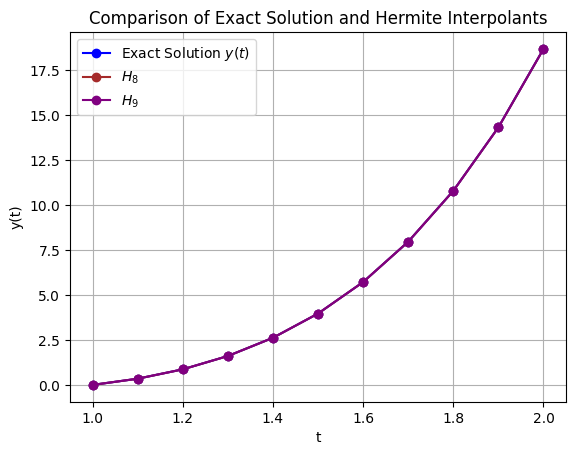

In [ ]:
import matplotlib.pyplot as plt

# Plot the exact solution
plt.plot(t, y(t), '-bo', label='Exact Solution $y(t)$')

# Plot Hermite interpolants
# YOUR CODE HERE
plt.plot(t, [H8(tt) for tt in t], '-o', color='brown', label='$H_8$')
plt.plot(t, [H9(tt) for tt in t], '-o', color='purple', label='$H_9$')

plt.title("Comparison of Exact Solution and Hermite Interpolants")
plt.xlabel("t")
plt.ylabel("y(t)")
plt.legend()
plt.grid(True)
plt.show()

### **Question 8b**

In this question, we will consider the **Gompertz** differential equation
	$
	N'(t) = \alpha \ln \dfrac{K}{N(t)} N(t)
	$


#### **[6 marks] Question 8b(i): Adams Predictor-Corrector for the Gompertz Equation**

Use the Adams predictor-corrector method with $h=0.5$ to approximate the solution.

**Task:**
Use the Adams fourth-order predictor-corrector method with a step size $h = 0.5$ to approximate the solution over $0 \leq t \leq 60$, with $N(0) = 4000$, $\alpha = 0.0439$, and $K = 12000$.

⸻

**Instructions**
1. Set the parameters:
	- Growth rate $\alpha$
	- Carrying capacity $K$
	-	Initial value $N(0)$
	-	Time interval $[a, b]$
	-	Number of steps $N$ (so that $h = (b-a)/N = 0.5$)
2. Define the right-hand side function for the ODE.
3. Apply the Adams predictor-corrector method (you may reuse your previously defined function).
4. Output the time steps and corresponding approximate solutions in a DataFrame.

⸻

**Code**

In [ ]:
import numpy as np
from pandas import DataFrame

# Parameters for the Gompertz model
# Complete your code
alpha = 0.0439
K = 12000
f = lambda t, N: alpha * N * np.log(K / N)
a = 0
b = 60
N = 120  # h = (b-a)/N = 0.5
initial_value = 4000  # N(0)

# Use the previously defined Adams predictor-corrector function
t, N_PC = Adams_Fourth_Order_Predictor_Corrector(f, a, b, N, initial_value) # YOUR CODE HERE

# Tabulate the results for inspection
result = {'$t_i$': t, 'Approximate solution': N_PC}
DataFrame(result)

,$t_i$,Approximate solution
0,0.0,4000.000000
1,0.5,4096.554152
2,1.0,4193.266963
3,1.5,4290.089092
4,2.0,4386.972107
...,...,...
116,58.0,11009.940881
117,58.5,11030.542992
118,59.0,11050.735117
119,59.5,11070.524622


#### **[6 marks] Question 8b(ii): Predicting Tumor Cell Thresholds**

Now that you have obtained the approximate solution $N(t)$ using the Adams predictor-corrector method, you will:
1. Plot $N(t)$ along with the horizontal lines $N=8000$ and $N=11000$ to visualize when these cell counts are reached.
2. Estimate the time (in months) when $N(t)$ reaches each threshold.

⸻

**Instructions**
- Plot the approximate tumor growth curve $N(t)$ over $0 \leq t \leq 60$ months.
- Overlay horizontal lines at $N = 8000$ and $N = 11000$.
-	Use the graph and your data to estimate the number of months required for the tumor to reach 8000 and 11000 cells, respectively.
-	Record your answers clearly.

⸻

**Code**

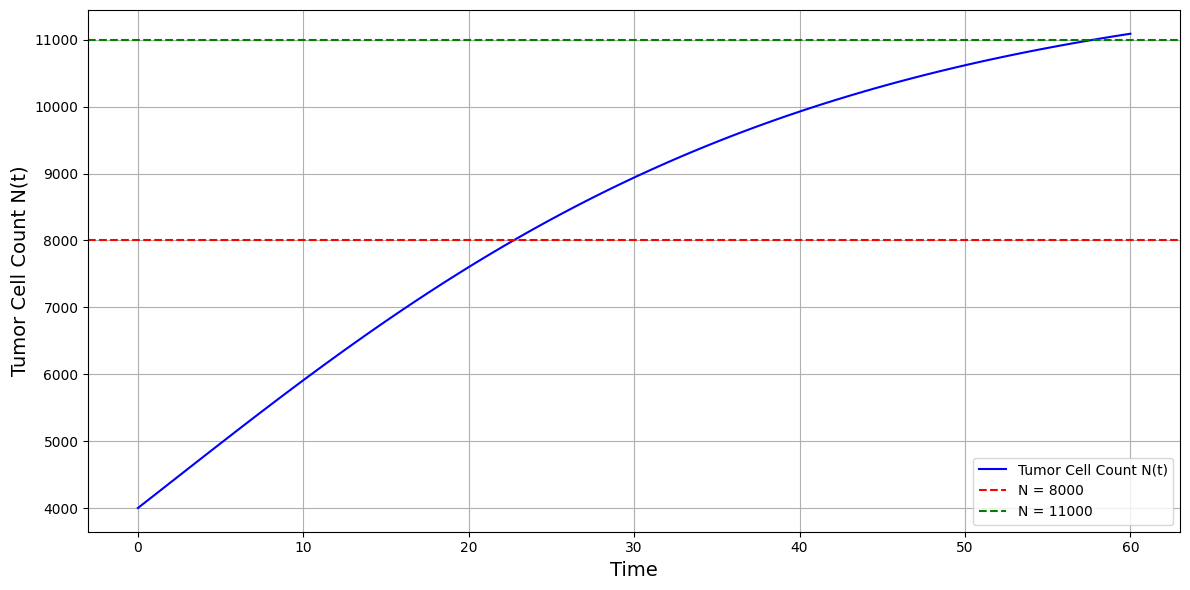

In [ ]:
import matplotlib.pyplot as plt
# YOUR CODE HERE
import numpy as np

plt.figure(figsize=(12, 6))
plt.plot(t, N_PC, label='Tumor Cell Count N(t)', color='blue')

plt.axhline(y=8000, color='red', linestyle='--', label='N = 8000')
plt.axhline(y=11000, color='green', linestyle='--', label='N = 11000')

plt.xlabel('Time', fontsize=14)
plt.ylabel('Tumor Cell Count N(t)', fontsize=14)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

def estimate_time(threshold, t, N_vals):
    for i in range(1, len(N_vals)):
        if N_vals[i-1] < threshold <= N_vals[i]:
            t1, t2 = t[i-1], t[i]
            N1, N2 = N_vals[i-1], N_vals[i]
            return t1 + (threshold - N1) * (t2 - t1) / (N2 - N1)
    return None

t_8000 = estimate_time(8000, t, N_PC)
t_11000 = estimate_time(11000, t, N_PC)

**Prediction**

Now, find the first index in your computed data where $N(t)$ exceeds 8000 and 11000, and report the corresponding time values:

In [ ]:
# Find time when N(t) first reaches or exceeds 8000 and 11000
# YOUR CODE HERE
print(f"N(t) reaches 8000 cells at approximately t = {t_8000:.2f}.")
print(f"N(t) reaches 11000 cells at approximately t = {t_11000:.2f}.")

N(t) reaches 8000 cells at approximately t = 22.71.
N(t) reaches 11000 cells at approximately t = 57.76.


Congratulations! You finished your exam. You can rest now and enjoy your upcoming Summer. Your exam score will be released within two business days. Hope that you enjoy the course in this semester!